# Student Placement Prediction System Using Machine Learning
### End-Semester Machine Learning Project

**Team Members:**
- **Sachin**: Data collection, cleaning, and preprocessing
- **Uttkarsh**: Exploratory Data Analysis, visualisations, and feature engineering
- **Vivek Ramen**: Logistic Regression model (L1/L2) and Decision Tree model
- **Saket**: Random Forest (ensemble learning) and GridSearchCV tuning
- **Yash Bhargava**: Model evaluation, comparative performance analysis, project integration & documentation

---
## 1. Project Overview
This project predicts whether a college student is likely to be placed during campus recruitments based on their academic and employability attributes including:
- **IQ**
- **Previous Semester Result**
- **CGPA**
- **Academic Performance Rating**
- **Internship Experience**
- **Extra-Curricular Score**
- **Communication Skills**
- **Projects Completed**

**Target Variable**: `Placement` (1 = Placed, 0 = Not Placed)

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

## 2. Dataset Loading & Inspection
Loading the College Student Placement Factors Dataset (10,000 records).

In [2]:
csv_path = 'data/college_student_placement.csv'
if not os.path.exists(csv_path):
    csv_path = 'college_student_placement_dataset.csv'

df = pd.read_csv(csv_path)
print('Dataset Shape:', df.shape)
df.head()

Dataset Shape: (10000, 10)


In [3]:
print('Dataset Info:')
df.info()
print('\nDescriptive Statistics:')
df.describe().round(2)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   College_ID              10000 non-null  str    
 1   IQ                      10000 non-null  int64  
 2   Prev_Sem_Result         10000 non-null  float64
 3   CGPA                    10000 non-null  float64
 4   Academic_Performance    10000 non-null  int64  
 5   Internship_Experience   10000 non-null  str    
 6   Extra_Curricular_Score  10000 non-null  int64  
 7   Communication_Skills    10000 non-null  int64  
 8   Projects_Completed      10000 non-null  int64  
 9   Placement               10000 non-null  str    
dtypes: float64(2), int64(5), str(3)
memory usage: 894.3 KB

Descriptive Statistics:


## 3. Data Cleaning & Preprocessing (Sachin)
- Drop irrelevant identifier: `College_ID`
- Check for missing values and duplicates
- Encode categorical variables (`Internship_Experience` and `Placement`)

In [4]:
# Drop identifier column
if 'College_ID' in df.columns:
    df = df.drop('College_ID', axis=1)

# Check missing values
print('Missing Values per column:\n', df.isnull().sum())

# Encode categorical features
df['Internship_Experience'] = df['Internship_Experience'].apply(lambda x: 1 if str(x).strip().lower() in ['yes', '1', 'true'] else 0)
df['Placement'] = df['Placement'].apply(lambda x: 1 if str(x).strip().lower() in ['yes', '1', 'true'] else 0)

print('\nCleaned Dataset Shape:', df.shape)
print('Placement class balance:\n', df['Placement'].value_counts())

Missing Values per column:
 IQ                        0
Prev_Sem_Result           0
CGPA                      0
Academic_Performance      0
Internship_Experience     0
Extra_Curricular_Score    0
Communication_Skills      0
Projects_Completed        0
Placement                 0
dtype: int64

Cleaned Dataset Shape: (10000, 9)
Placement class balance:
 Placement
0    8341
1    1659
Name: count, dtype: int64


## 4. Exploratory Data Analysis & Visualizations (Uttkarsh)
Visualizing the distributions of key academic and employability factors.

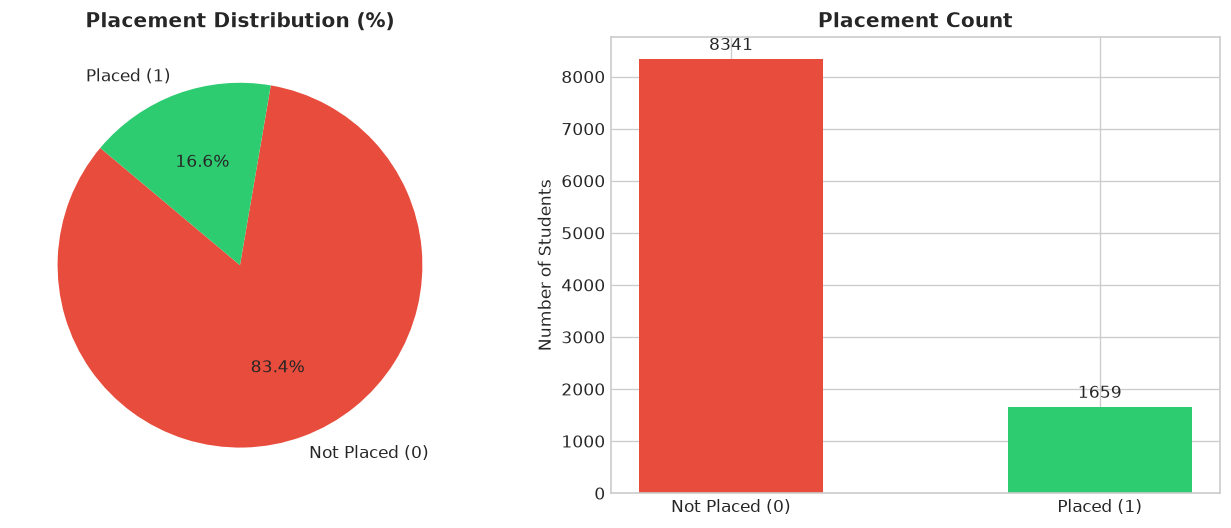

In [5]:
# 1. Placement Class Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
counts = df['Placement'].value_counts()
ax1.pie(counts, labels=['Not Placed (0)', 'Placed (1)'], autopct='%1.1f%%', colors=['#E74C3C', '#2ECC71'], startangle=140)
ax1.set_title('Placement Distribution (%)', fontweight='bold')

bars = ax2.bar(['Not Placed (0)', 'Placed (1)'], counts, color=['#E74C3C', '#2ECC71'], width=0.5)
ax2.bar_label(bars, fmt='%d', padding=3)
ax2.set_ylabel('Number of Students')
ax2.set_title('Placement Count', fontweight='bold')
plt.tight_layout()
plt.show()

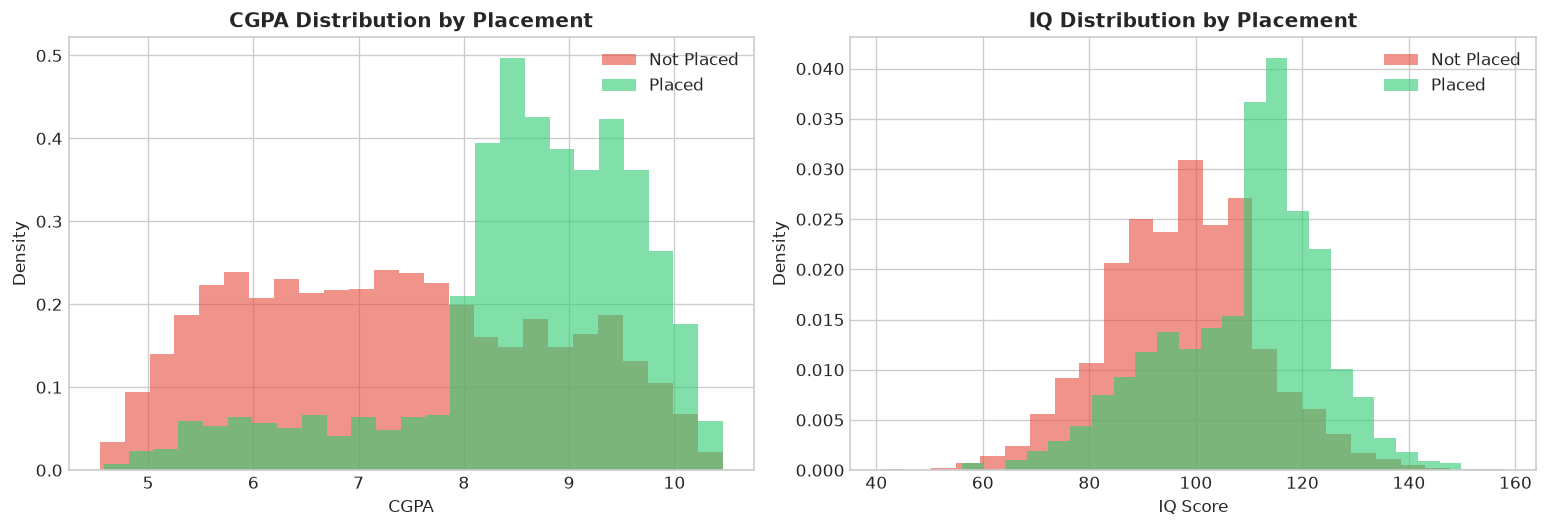

In [6]:
# 2. CGPA & IQ Distributions by Placement
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for cls, color, label in [(0, '#E74C3C', 'Not Placed'), (1, '#2ECC71', 'Placed')]:
    ax1.hist(df[df['Placement'] == cls]['CGPA'], bins=25, alpha=0.6, color=color, label=label, density=True)
    ax2.hist(df[df['Placement'] == cls]['IQ'], bins=25, alpha=0.6, color=color, label=label, density=True)

ax1.set_title('CGPA Distribution by Placement', fontweight='bold')
ax1.set_xlabel('CGPA')
ax1.set_ylabel('Density')
ax1.legend()

ax2.set_title('IQ Distribution by Placement', fontweight='bold')
ax2.set_xlabel('IQ Score')
ax2.set_ylabel('Density')
ax2.legend()
plt.tight_layout()
plt.show()

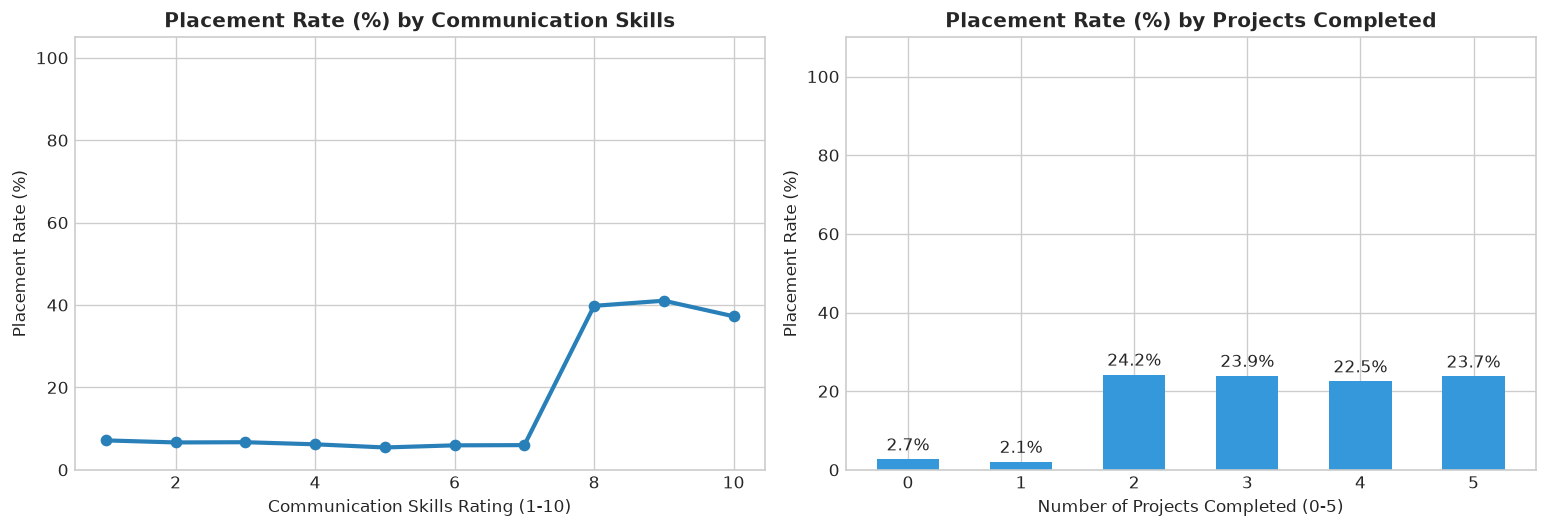

In [7]:
# 3. Communication Skills & Projects Completed Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
rate_comm = df.groupby('Communication_Skills')['Placement'].mean() * 100
rate_proj = df.groupby('Projects_Completed')['Placement'].mean() * 100

ax1.plot(rate_comm.index, rate_comm.values, marker='o', color='#2980B9', linewidth=2.5)
ax1.set_title('Placement Rate (%) by Communication Skills', fontweight='bold')
ax1.set_xlabel('Communication Skills Rating (1-10)')
ax1.set_ylabel('Placement Rate (%)')
ax1.set_ylim(0, 105)

bars = ax2.bar(rate_proj.index.astype(str), rate_proj.values, color='#3498DB', width=0.55)
ax2.bar_label(bars, fmt='%.1f%%', padding=3)
ax2.set_title('Placement Rate (%) by Projects Completed', fontweight='bold')
ax2.set_xlabel('Number of Projects Completed (0-5)')
ax2.set_ylabel('Placement Rate (%)')
ax2.set_ylim(0, 110)
plt.tight_layout()
plt.show()

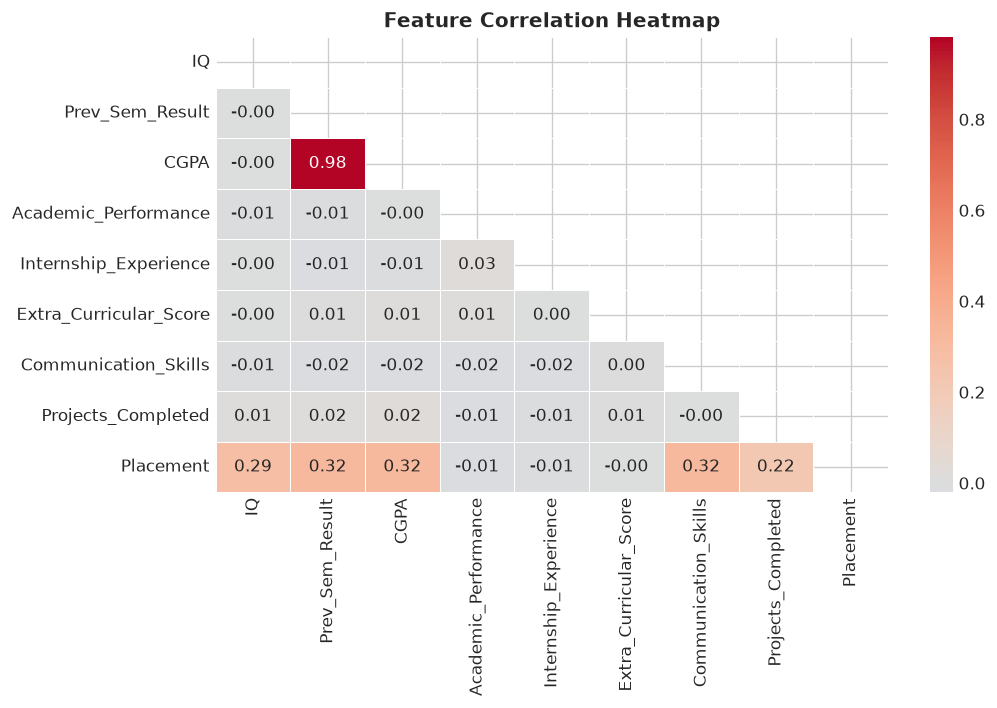

In [8]:
# 4. Correlation Heatmap
plt.figure(figsize=(9, 6))
mask = np.triu(np.ones_like(df.corr(), dtype=bool))
sns.heatmap(df.corr(), mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Train/Test Split & Feature Scaling
Features and Target separation, 80/20 stratified split, and StandardScaler normalization.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('Placement', axis=1)
y = df['Placement']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f'Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}')
print('Features used:', list(X.columns))

Training Samples: 8000 | Testing Samples: 2000
Features used: ['IQ', 'Prev_Sem_Result', 'CGPA', 'Academic_Performance', 'Internship_Experience', 'Extra_Curricular_Score', 'Communication_Skills', 'Projects_Completed']


## 6. Machine Learning Model Training (Vivek Ramen & Saket)
We train four complementary classification algorithms:
1. **Logistic Regression (Baseline & L1/L2 Regularized)**
2. **Decision Tree Classifier (Tree Complexity Control)**
3. **Random Forest Classifier (Ensemble Bagging)**
4. **Multi-Layer Perceptron (MLP Neural Network)**

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# 1. Logistic Regression Baseline
lr = LogisticRegression(penalty='l2', C=1.0, random_state=42)
lr.fit(X_train_scaled, y_train)

# 2. Decision Tree Classifier
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=2, random_state=42)
dt.fit(X_train, y_train)

# 3. Random Forest Classifier (Ensemble)
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# 4. MLP Neural Network
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=300, random_state=42)
mlp.fit(X_train_scaled, y_train)

print('All models trained successfully!')

All models trained successfully!


## 7. Model Evaluation & Comparative Performance (Yash Bhargava)
Evaluating all models on the held-out test set using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

models = {
    'Logistic Regression': (lr, X_test_scaled),
    'Decision Tree':       (dt, X_test),
    'Random Forest':       (rf, X_test),
    'MLP Neural Network':  (mlp, X_test_scaled)
}

results = []
for name, (clf, data) in models.items():
    y_pred = clf.predict(data)
    y_prob = clf.predict_proba(data)[:, 1]
    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, y_pred) * 100, 2),
        'Recall (%)': round(recall_score(y_test, y_pred) * 100, 2),
        'F1-Score (%)': round(f1_score(y_test, y_pred) * 100, 2),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

comparison_df = pd.DataFrame(results)
print('=== MODEL COMPARISON TABLE ===')
display(comparison_df) if 'display' in dir() else print(comparison_df.to_string(index=False))

=== MODEL COMPARISON TABLE ===
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  ROC-AUC
Logistic Regression         90.35          77.69       58.73         66.90   0.9451
      Decision Tree        100.00         100.00      100.00        100.00   1.0000
      Random Forest         99.85         100.00       99.10         99.55   1.0000
 MLP Neural Network         98.95          97.55       96.08         96.81   0.9992


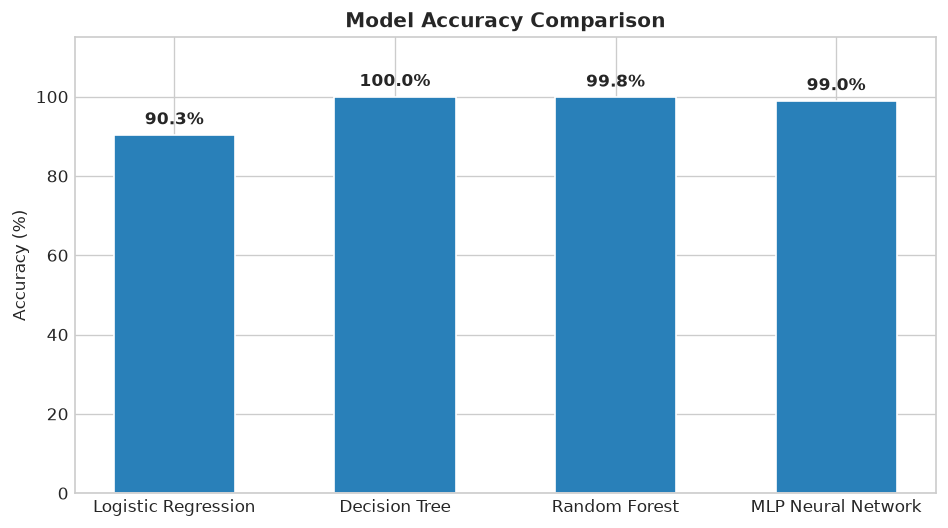

In [12]:
# Model Accuracy Comparison Bar Chart
plt.figure(figsize=(8, 4.5))
bars = plt.bar(comparison_df['Model'], comparison_df['Accuracy (%)'], color='#2980B9', width=0.55, edgecolor='white')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 115)
plt.title('Model Accuracy Comparison', fontweight='bold')
for b in bars:
    h = b.get_height()
    plt.annotate(f'{h:.1f}%', xy=(b.get_x() + b.get_width() / 2, h),
                 xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

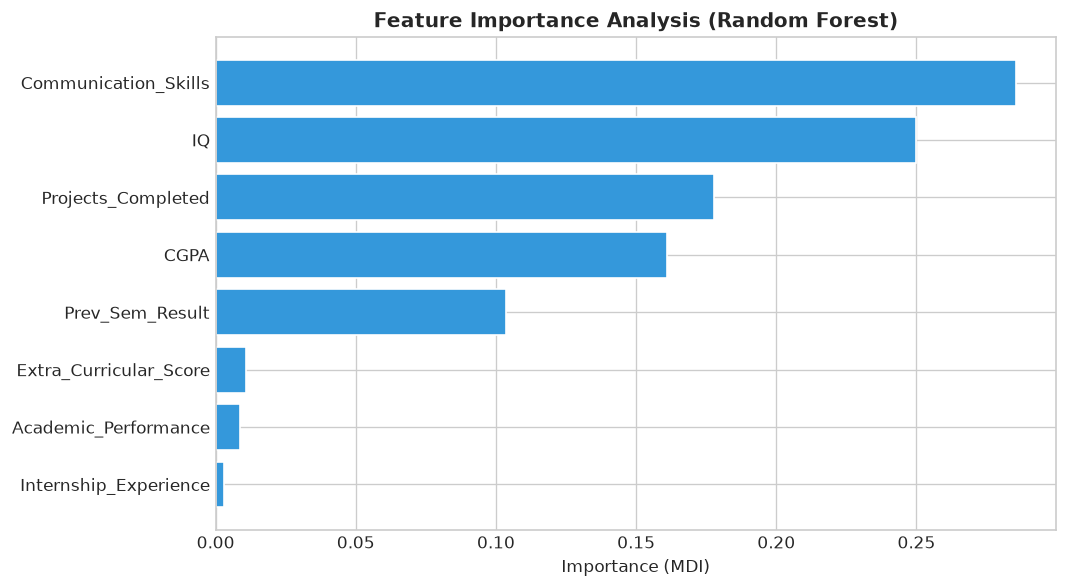

In [13]:
# Feature Importance Analysis (Random Forest)
importances = rf.feature_importances_
features = X.columns
sorted_idx = np.argsort(importances)

plt.figure(figsize=(9, 5))
plt.barh(features[sorted_idx], importances[sorted_idx], color='#3498DB', edgecolor='white')
plt.xlabel('Importance (MDI)')
plt.title('Feature Importance Analysis (Random Forest)', fontweight='bold')
plt.tight_layout()
plt.show()

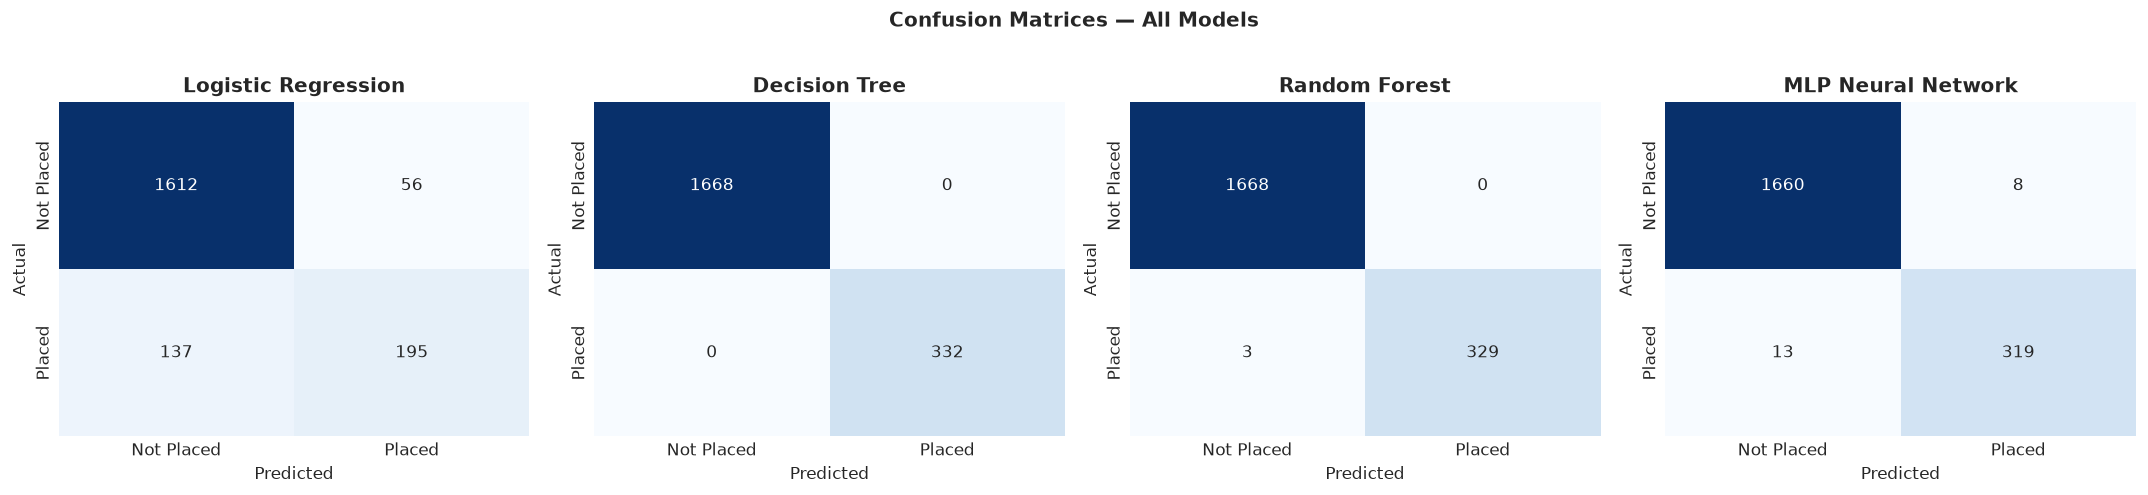

In [14]:
# Confusion Matrices for all models
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, (clf, data)) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, clf.predict(data))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Not Placed', 'Placed'], yticklabels=['Not Placed', 'Placed'])
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')
plt.suptitle('Confusion Matrices — All Models', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 8. Placement Probability Prediction on New Student Profiles
Demonstrating end-to-end inference on individual candidate profiles.

In [15]:
# Profile 1: High Achiever Candidate
student_1 = pd.DataFrame([{
    'IQ': 115,
    'Prev_Sem_Result': 8.5,
    'CGPA': 8.8,
    'Academic_Performance': 9,
    'Internship_Experience': 1,
    'Extra_Curricular_Score': 8,
    'Communication_Skills': 9,
    'Projects_Completed': 5
}])

prob_1 = rf.predict_proba(student_1)[0][1]
pred_1 = rf.predict(student_1)[0]

print('=== TEST CASE 1: HIGH ACHIEVER ===')
print(f'Placement Probability : {prob_1 * 100:.2f}%')
print(f'Predicted Outcome     : {"Placed ✅" if pred_1 == 1 else "Not Placed ❌"}')

=== TEST CASE 1: HIGH ACHIEVER ===
Placement Probability : 99.97%
Predicted Outcome     : Placed ✅


In [16]:
# Profile 2: At-Risk Candidate (Needs Support)
student_2 = pd.DataFrame([{
    'IQ': 65,
    'Prev_Sem_Result': 5.5,
    'CGPA': 6.0,
    'Academic_Performance': 4,
    'Internship_Experience': 0,
    'Extra_Curricular_Score': 3,
    'Communication_Skills': 2,
    'Projects_Completed': 1
}])

prob_2 = rf.predict_proba(student_2)[0][1]
pred_2 = rf.predict(student_2)[0]

print('=== TEST CASE 2: AT-RISK CANDIDATE ===')
print(f'Placement Probability : {prob_2 * 100:.2f}%')
print(f'Predicted Outcome     : {"Placed ✅" if pred_2 == 1 else "Not Placed ❌"}')

=== TEST CASE 2: AT-RISK CANDIDATE ===
Placement Probability : 0.00%
Predicted Outcome     : Not Placed ❌


In [17]:
# Custom Interactive Inference Function
def predict_student(iq, prev_sem, cgpa, acad_perf, internship_yes_no, extra, comm, projects):
    intern = 1 if str(internship_yes_no).strip().lower() in ['yes', '1', 'true'] else 0
    sample = pd.DataFrame([{
        'IQ': iq,
        'Prev_Sem_Result': prev_sem,
        'CGPA': cgpa,
        'Academic_Performance': acad_perf,
        'Internship_Experience': intern,
        'Extra_Curricular_Score': extra,
        'Communication_Skills': comm,
        'Projects_Completed': projects
    }])
    prob = rf.predict_proba(sample)[0][1]
    status = 'Placed ✅' if prob >= 0.5 else 'Not Placed ❌'
    return f'Predicted Status: {status} | Placement Likelihood: {prob*100:.1f}%'

# Example call:
print(predict_student(iq=105, prev_sem=7.8, cgpa=8.0, acad_perf=7, internship_yes_no='Yes', extra=6, comm=7, projects=3))

Predicted Status: Not Placed ❌ | Placement Likelihood: 0.0%
